# V4 — Tối ưu S6 Warp/Blend (`warp_blend_v4_kernel`)

Owner: Thịnh. V4 kế thừa **đúng V3 đã merge** (gồm V2 S4 và V3 S6 compressed crop stack), giữ nguyên S1–S5 (kể cả Gaussian blur của V1/V3), và **chỉ tối ưu kernel warp/blend ở S6** — bottleneck chính chiếm ~73% tổng thời gian kernel ở 4K.

Các tối ưu chính trong `v4_stage6.cu`:
- Đóng gói ảnh `B` sang `uchar4` trên GPU (`pack_rgb_to_uchar4_kernel`) để đọc 4 lân cận bằng 4 lệnh `__ldg` thẳng hàng thay vì 12 lệnh đọc 1-byte rời rạc.
- Dùng 1 phép chia nghịch đảo `double` (`inv_z = 1.0 / z`) khi chiếu ngược giữ nguyên biên/làm tròn, sau đó chuyển nội suy bilinear và feather blending sang `float` (tránh bottleneck FP64 tỷ lệ 1:32 trên Tesla T4).
- Block `32×8` (đủ 1 warp theo chiều ngang) giúp ghi `pano`, `valid` và đọc `A` coalesced hoàn toàn, kèm nhánh thoát nhanh cho pixel chỉ thuộc `A` hoặc ngoài cả `A` và `B`.

Chọn Colab **GPU**, rồi Run all sau khi source V4 đã được push lên branch `v4`. Notebook không chứa số đo giả định. Chốt hiệu quả V4 chỉ sau parity, 12 case timing và profiler V3/V4.

In [1]:
from pathlib import Path
import csv
import datetime
import json
import os
import re
import shlex
import shutil
import subprocess
import sys
from statistics import geometric_mean

REPO_URL = "https://github.com/nganbee/panorama-stitching-project.git"
BRANCH = "v4_1"
REPO = Path("/content/panorama-stitching-project")
UPDATE_REPO = True  # False: giữ source đã upload/chỉnh tại Colab.
RUNS = 5
RUN_PROFILER = True  # Có nsys thì profile; thiếu tool ghi NOT RUN.
RUN_REVERSE_SWEEP = True  # True: đo thêm một sweep đảo thứ tự V3/V4.
COMMAND_LOG_DIR = None
COMMAND_INDEX = 0

def run(args, check=True, log=None):
    # Capture + print explicitly so subprocess output is retained in the ipynb.
    global COMMAND_INDEX
    command = shlex.join([str(a) for a in args])
    print("$", command, flush=True)
    if log is None and COMMAND_LOG_DIR is not None:
        COMMAND_INDEX += 1
        log = COMMAND_LOG_DIR / f"command_{COMMAND_INDEX:03d}.log"
    stream = None
    try:
        if log is not None:
            log = Path(log)
            log.parent.mkdir(parents=True, exist_ok=True)
            stream = log.open("w", encoding="utf-8")
            stream.write("$ " + command + "\n")
        with subprocess.Popen([str(a) for a in args], text=True,
                              stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                              bufsize=1) as process:
            for line in process.stdout:
                print(line, end="", flush=True)
                if stream is not None:
                    stream.write(line)
                    stream.flush()
            code = process.wait()
    finally:
        if stream is not None:
            stream.close()
    if check and code:
        raise RuntimeError(f"Command failed ({code}); log: {log}")
    return code

if not REPO.exists():
    run(["git", "clone", "--branch", BRANCH, REPO_URL, REPO])
os.chdir(REPO)
if UPDATE_REPO:
    dirty = subprocess.check_output(["git", "status", "--porcelain"], text=True).strip()
    if dirty:
        print("Có thay đổi local: giữ nguyên checkout, không tự pull.")
    else:
        run(["git", "fetch", "origin", BRANCH])
        run(["git", "checkout", BRANCH])
        ancestor = subprocess.run(["git", "merge-base", "--is-ancestor", "HEAD", f"origin/{BRANCH}"])
        if ancestor.returncode:
            raise RuntimeError("Checkout đã lệch lịch sử (có thể sau rebase). Dùng thư mục REPO mới để clone; không tự reset mất dữ liệu.")
        run(["git", "merge", "--ff-only", f"origin/{BRANCH}"])
required = ["src/cuda/v2_pipeline.cu", "src/stage_implementations/v2_stage4.cu",
            "src/cuda/v3_pipeline.cu", "src/stage_implementations/v3_stage6.cu",
            "src/stage_implementations/v4_stage6.cu"]
assert all(Path(p).is_file() for p in required), "Thiếu source V2/V3/V4 tích lũy."
assert RUNS >= 5
STAMP = datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
SESSION_DIR = Path("out") / f"v4_inspect_{STAMP}"
SESSION_DIR.mkdir(parents=True)
COMMAND_LOG_DIR = SESSION_DIR / "commands"
RESULTS = SESSION_DIR / "benchmark"  # benchmark script sẽ tạo thư mục này.
Path("build").mkdir(exist_ok=True)
run(["git", "status", "--short"])
run(["git", "branch", "--show-current"])
run(["git", "rev-parse", "HEAD"])
print("Session:", SESSION_DIR)


$ git clone --branch v4_1 https://github.com/nganbee/panorama-stitching-project.git /content/panorama-stitching-project
Cloning into '/content/panorama-stitching-project'...
$ git fetch origin v4_1
From https://github.com/nganbee/panorama-stitching-project
 * branch            v4_1       -> FETCH_HEAD
$ git checkout v4_1
Already on 'v4_1'
Your branch is up to date with 'origin/v4_1'.
$ git merge --ff-only origin/v4_1
Already up to date.
$ git status --short
$ git branch --show-current
v4_1
$ git rev-parse HEAD
b09c26fc2814d57190d56c53ef32a9efa1bbc24b
Session: out/v4_inspect_20261124T112533_222735Z


## 1. GPU, compiler và build chung

Giữ `--fmad=false`, không dùng fast math. Một binary cung cấp V0/V1/V2/V3/V4; mọi bản dùng cùng input, flags và GPU session. Block warp mặc định 32×8. Có thể build lại với kích thước block khác (ví dụ 16×16 hoặc 32×16) qua `WARP_BLOCK_FLAGS`, chạy lại toàn bộ parity và lưu kết quả vào thư mục riêng.

In [2]:
run(["nvidia-smi"], log=SESSION_DIR / "nvidia-smi.log")
GPU = subprocess.check_output(["nvidia-smi", "--query-gpu=name,uuid,driver_version",
                               "--format=csv,noheader"], text=True).strip()
print("GPU:", GPU)
run(["nvcc", "--version"])
run(["g++", "--version"])
WARP_BLOCK_FLAGS = []  # e.g. ["-DPANORAMA_V4_WARP_BLOCK_X=16", "-DPANORAMA_V4_WARP_BLOCK_Y=16"]
FLAGS = ["nvcc", "-O2", "-std=c++17", "--fmad=false",
         "-DPANORAMA_WITH_CUDA", "-DPANORAMA_WITH_V2", "-DPANORAMA_WITH_V3", "-DPANORAMA_WITH_V4",
         "-Isrc/core_headers", "-Isrc/libraries"] + WARP_BLOCK_FLAGS
SOURCES = [
    "src/integration/v0_pipeline.cpp",
    "src/stage_implementations/v0_stage12.cpp",
    "src/stage_implementations/v0_stage34.cpp",
    "src/stage_implementations/v0_stage5.cpp",
    "src/stage_implementations/v0_stage6.cpp",
    "src/stage_implementations/v1_stage12.cu",
    "src/stage_implementations/v1_stage34.cu",
    "src/stage_implementations/v1_stage5.cu",
    "src/stage_implementations/v1_stage6.cu",
    "src/stage_implementations/v2_stage4.cu",
    "src/stage_implementations/v3_stage6.cu",
    "src/stage_implementations/v4_stage6.cu",
    "src/cuda/cuda_pipeline.cu", "src/cuda/v2_pipeline.cu", "src/cuda/v3_pipeline.cu", "src/cuda/v4_pipeline.cu",
    "src/libraries/stb_impl.cpp",
]
run(FLAGS + ["src/integration/main.cpp"] + SOURCES + ["-o", "build/stitch_v4"])
run(["build/stitch_v4", "--list-versions"])
run(["build/stitch_v4", "--dump-params"])
(SESSION_DIR / "build_flags.json").write_text(json.dumps(FLAGS, indent=2), encoding="utf-8")
(SESSION_DIR / "environment.json").write_text(json.dumps({
    "gpu": GPU, "commit": subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip(),
    "worktree": subprocess.check_output(["git", "status", "--short"], text=True),
    "flags": FLAGS, "runs": RUNS, "warmup_runs": 1,
}, indent=2), encoding="utf-8")


$ nvidia-smi
Tue Nov 24 11:25:33 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+----------------------------------

427

## 2. Parity S6 warp riêng (identity, shift, perspective, partial blocks, input lỗi)

Test `v4_warp_blend` so với V0/V3 trên nhiều kích thước không chia hết block (`1×1`, `17×19`, `31×33`, `33×9`, `193×157`), nhiều pattern ảnh, phép biến đổi identity/shift/perspective và input lỗi (ảnh rỗng, homography suy biến). Yêu cầu kích thước crop khớp tuyệt đối với V0/V3 và sai số từng kênh RGB ≤1 mức.

In [3]:
run(FLAGS + [
    "src/tools/v4/test_v4_stage6.cpp",
    "src/stage_implementations/v0_stage6.cpp",
    "src/stage_implementations/v1_stage6.cu",
    "src/stage_implementations/v3_stage6.cu",
    "src/stage_implementations/v4_stage6.cu",
    "-o", "build/test_v4_stage6",
])
run(["build/test_v4_stage6"])
run(["build/stitch_v4", "--selftest", "--version", "4"])

$ nvcc -O2 -std=c++17 --fmad=false -DPANORAMA_WITH_CUDA -DPANORAMA_WITH_V2 -DPANORAMA_WITH_V3 -DPANORAMA_WITH_V4 -Isrc/core_headers -Isrc/libraries src/tools/v4/test_v4_stage6.cpp src/stage_implementations/v0_stage6.cpp src/stage_implementations/v1_stage6.cu src/stage_implementations/v3_stage6.cu src/stage_implementations/v4_stage6.cu -o build/test_v4_stage6
$ build/test_v4_stage6
PASS: V4 S6 warp vs V0/V3 (identity, shift, perspective, partial blocks, invalid inputs)
$ build/stitch_v4 --selftest --version 4
V4 CUDA S6 warp smoke selftest PASS (run full V4 tests for acceptance)


0

## 3. Parity toàn pipeline V4 so với V0/V3

Test identity, dịch chuyển, input lỗi và no-feature; sau đó chạy lại để kiểm tra trạng thái profiler. S1–S5 giữ nguyên V3 (keypoints/matches/inliers và H khớp tuyệt đối V3, sai số chiếu H ≤1e-3 px so với V0); S6 kích thước crop khớp tuyệt đối và RGB ≤1 mức so với V0/V3. Test timing kiểm tra tổng stage bằng `kernel_total`. Case V0 thất bại không được đánh dấu panorama parity PASS.

In [4]:
run(FLAGS + ["src/tools/v4/test_v4_pipeline.cpp"] + SOURCES + ["-o", "build/test_v4_pipeline"])
run(["build/test_v4_pipeline"])


$ nvcc -O2 -std=c++17 --fmad=false -DPANORAMA_WITH_CUDA -DPANORAMA_WITH_V2 -DPANORAMA_WITH_V3 -DPANORAMA_WITH_V4 -Isrc/core_headers -Isrc/libraries src/tools/v4/test_v4_pipeline.cpp src/integration/v0_pipeline.cpp src/stage_implementations/v0_stage12.cpp src/stage_implementations/v0_stage34.cpp src/stage_implementations/v0_stage5.cpp src/stage_implementations/v0_stage6.cpp src/stage_implementations/v1_stage12.cu src/stage_implementations/v1_stage34.cu src/stage_implementations/v1_stage5.cu src/stage_implementations/v1_stage6.cu src/stage_implementations/v2_stage4.cu src/stage_implementations/v3_stage6.cu src/stage_implementations/v4_stage6.cu src/cuda/cuda_pipeline.cu src/cuda/v2_pipeline.cu src/cuda/v3_pipeline.cu src/cuda/v4_pipeline.cu src/libraries/stb_impl.cpp -o build/test_v4_pipeline
$ build/test_v4_pipeline
  panorama MAE=0.000000000
  panorama MAE=0.000000000
PASS: V4 pipeline vs V0/V3 (193x157 + 193x157, matches=287 inliers=287)
  panorama MAE=0.000000000
  panorama MAE=0.000

0

## 4. Compute Sanitizer

Chạy cả `memcheck` và `synccheck` cho test S6 warp để phát hiện truy cập ngoài biên / đồng bộ reduction; pipeline test chạy `memcheck`. Nếu tool không có, ghi rõ NOT RUN thay vì PASS.

In [5]:
if shutil.which("compute-sanitizer"):
    run(["compute-sanitizer", "--tool", "memcheck", "--error-exitcode", "1", "build/test_v4_stage6"])
    run(["compute-sanitizer", "--tool", "synccheck", "--error-exitcode", "1", "build/test_v4_stage6"])
    run(["compute-sanitizer", "--tool", "memcheck", "--error-exitcode", "1", "build/test_v4_pipeline"])
else:
    print("NOT RUN: Compute Sanitizer unavailable. Chưa nghiệm thu memory/synchronization safety.")


$ compute-sanitizer --tool memcheck --error-exitcode 1 build/test_v4_stage6
========= COMPUTE-SANITIZER
PASS: V4 S6 warp vs V0/V3 (identity, shift, perspective, partial blocks, invalid inputs)
========= ERROR SUMMARY: 0 errors
$ compute-sanitizer --tool synccheck --error-exitcode 1 build/test_v4_stage6
========= COMPUTE-SANITIZER
PASS: V4 S6 warp vs V0/V3 (identity, shift, perspective, partial blocks, invalid inputs)
========= ERROR SUMMARY: 0 errors
$ compute-sanitizer --tool memcheck --error-exitcode 1 build/test_v4_pipeline
========= COMPUTE-SANITIZER
  panorama MAE=0.000000000
  panorama MAE=0.000000000
PASS: V4 pipeline vs V0/V3 (193x157 + 193x157, matches=287 inliers=287)
  panorama MAE=0.000000000
  panorama MAE=0.000000000
PASS: V4 pipeline vs V0/V3 (193x157 + 193x157, matches=268 inliers=268)
  panorama MAE=0.000000000
  panorama MAE=0.000000000
PASS: V4 pipeline vs V0/V3 (193x157 + 193x157, matches=287 inliers=287)
PASS: V4 expected error cases
========= ERROR SUMMARY: 0 erro

## 5. Baseline V3: xác nhận tỷ trọng S6 warp_blend trước phép đo V4

CLI tự chạy **1 warm-up + tối thiểu 5 lần đo**, JSON là trung bình. Đây là timing kernel; H2D/D2H riêng, E2E gồm allocation/launch/sync/copy. Đọc/ghi ảnh nằm ngoài E2E. Mục này xác nhận S6 (`warp_blend`) là bottleneck kernel lớn nhất ở V3 (~73% kernel total ở 4K).

In [6]:
BASELINE = SESSION_DIR / "v3_baseline.json"
LEFT = "dataset/location1/large_4k/1.jpg"
RIGHT = "dataset/location1/large_4k/2.jpg"
run(["build/stitch_v4", LEFT, RIGHT, SESSION_DIR / "v3_baseline.png",
     "--version", "3", "--runs", RUNS, "--json", BASELINE], log=SESSION_DIR / "v3_baseline.log")
baseline = json.loads(BASELINE.read_text(encoding="utf-8"))
t = baseline["timings_ms"]
print("GPU:", GPU)
print(f"V3 warp_blend={t['warp_blend']:.4f} ms; E2E={t['end_to_end']:.4f} ms")
print(f"S6 (warp_blend) share: {100*t['warp_blend']/t['kernel_total']:.2f}% of kernel; "
      f"{100*t['warp_blend']/t['end_to_end']:.2f}% of E2E")
for name, ms in sorted(baseline["stage_timings_ms"].items(), key=lambda p: p[1], reverse=True):
    print(f"{name}: {ms:.4f} ms ({100*ms/t['kernel_total']:.2f}% kernel)")
print("Bảng đủ 12 case ở mục 7.")

$ build/stitch_v4 dataset/location1/large_4k/1.jpg dataset/location1/large_4k/2.jpg out/v4_inspect_20261124T112533_222735Z/v3_baseline.png --version 3 --runs 5 --json out/v4_inspect_20261124T112533_222735Z/v3_baseline.json
version=3 runs=5 imageA=3840x2160 imageB=3840x2160
keypoints_A=3000 keypoints_B=3000 matches=1393 inliers=865
panorama=9088x2160 inlier_ratio=0.621
avg_ms gray=0.512 blur=1.352 harris=4.098 nms_topk=1.344 describe=0.528 match=0.632 ransac=12.649 warp_blend=57.334 h2d=83.059 d2h=56.933 kernel_total=78.451 end_to_end=375.030
GPU: Tesla T4, GPU-cb2554e3-0e82-6a06-cb8a-0af77ec143e2, 580.82.07
V3 warp_blend=57.3342 ms; E2E=375.0299 ms
S6 (warp_blend) share: 73.08% of kernel; 15.29% of E2E
S6: 57.3342 ms (73.08% kernel)
S5: 12.6494 ms (16.12% kernel)
S2: 5.4430 ms (6.94% kernel)
S1: 1.8641 ms (2.38% kernel)
S4: 0.6325 ms (0.81% kernel)
S3: 0.5282 ms (0.67% kernel)
Bảng đủ 12 case ở mục 7.


## 6. Đủ 12 case: correctness + V0/V3/V4 timing + JSON

Mỗi case chạy parity riêng, rồi V0/V3/V4 có warm-up và ≥5 timed runs. Mọi ca lỗi được lưu log, ghi failed; script vẫn đo các case còn lại. `summary.csv/json` chứa stage bottleneck, `warp_blend`/E2E speedup và transfer timings. Kết quả tăng tốc dưới 1 được giữ để phân tích. Tránh so số đo lấy từ các GPU session khác nhau.

In [7]:
benchmark_status = run([sys.executable, "src/tools/v4/benchmark_v4.py",
    "--binary", "build/stitch_v4", "--parity", "build/test_v4_pipeline",
    "--runs", RUNS, "--output", RESULTS], check=False, log=SESSION_DIR / "benchmark.log")
print("Benchmark exit code:", benchmark_status)
if not (RESULTS / "summary.csv").is_file():
    raise RuntimeError("Benchmark chưa tạo summary.csv; xem benchmark.log.")
if RUN_REVERSE_SWEEP:
    REVERSE_RESULTS = SESSION_DIR / "benchmark_reverse"
    reverse_status = run([sys.executable, "src/tools/v4/benchmark_v4.py",
        "--binary", "build/stitch_v4", "--parity", "build/test_v4_pipeline",
        "--runs", RUNS, "--reverse-order", "--output", REVERSE_RESULTS],
        check=False, log=SESSION_DIR / "benchmark_reverse.log")
    print("Reverse sweep exit code:", reverse_status)


$ /usr/bin/python3 src/tools/v4/benchmark_v4.py --binary build/stitch_v4 --parity build/test_v4_pipeline --runs 5 --output out/v4_inspect_20261124T112533_222735Z/benchmark
Reports: /content/panorama-stitching-project/out/v4_inspect_20261124T112533_222735Z/benchmark

CASE location1_720p
  panorama MAE=0.000002865
  panorama MAE=0.000002865
PASS: V4 pipeline vs V0/V3 (1280x720 + 1280x720, matches=620 inliers=448)
GPU: Tesla T4, GPU-cb2554e3-0e82-6a06-cb8a-0af77ec143e2, 580.82.07 case: location1_720p version: 0
version=0 runs=5 imageA=1280x720 imageB=1280x720
keypoints_A=1311 keypoints_B=1474 matches=620 inliers=448
panorama=2909x720 inlier_ratio=0.723
avg_ms gray=3.539 blur=53.264 harris=77.492 nms_topk=6.094 describe=9.384 match=782.487 ransac=18.652 warp_blend=262.175 h2d=0.000 d2h=0.000 kernel_total=0.000 end_to_end=1213.090
GPU: Tesla T4, GPU-cb2554e3-0e82-6a06-cb8a-0af77ec143e2, 580.82.07 case: location1_720p version: 3
version=3 runs=5 imageA=1280x720 imageB=1280x720
keypoints_A=13

## 7. Inspect timing V0/V3/V4 — từng bước, stage và E2E

Mọi bảng dùng JSON **cùng session**, không ghép số đo từ notebook V3 cũ. Đổi RESULTS thành thư mục kết quả cũ rồi chạy lại mục này để inspect mà không cần benchmark lại. CSV đầy đủ xuất vào RESULTS/inspection/.

S1 = gray + blur; S2 = harris + nms_topk. Thời gian GPU trong JSON là CUDA-event; V0 dùng CPU timer. Kernel total đã bao gồm các bước GPU, không cộng lại. Residual = E2E − kernel − H2D − D2H, gồm allocation/free, điều phối, synchronization và phần chưa hạch toán; không gọi residual là kernel hay thời gian CPU thuần.


In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 90)
TIMING_FIELDS = ["gray", "blur", "harris", "nms_topk", "describe", "match", "ransac",
                 "warp_blend", "kernel_total", "h2d", "d2h", "end_to_end"]
STEPS = TIMING_FIELDS[:8]
STAGES = ["S1", "S2", "S3", "S4", "S5", "S6"]
INSPECTION_DIR = RESULTS / "inspection"
INSPECTION_DIR.mkdir(exist_ok=True)
summary = pd.read_csv(RESULTS / "summary.csv")
environment_path = RESULTS / "environment.json"
environment = json.loads(environment_path.read_text(encoding="utf-8")) if environment_path.is_file() else {}
GPU_LABEL = environment.get("gpu_identity", environment.get("gpu", "Không có GPU metadata trong thư mục này"))
print("Reports:", RESULTS, "\nGPU:", GPU_LABEL)
display(summary[["case", "status", "parity"]])
failures = summary.loc[summary.status.ne("ok") | summary.parity.ne("pass")]
print(f"Verified successful cases: {len(summary)-len(failures)}/{len(summary)}; expected: 12")
if not failures.empty:
    display(failures)
    print("Giữ ca lỗi trong báo cáo; không tính speedup hoặc tuyên bố parity PASS cho ca đó.")
records = []
for item in summary.to_dict("records"):
    for version in (0, 3, 4):
        report_path = RESULTS / f"{item['case']}_v{version}.json"
        if not report_path.is_file():
            continue
        try:
            report = json.loads(report_path.read_text(encoding="utf-8"))
        except (OSError, ValueError) as error:
            report = {"status": "invalid_json", "error": str(error)}
        record = {"case": item["case"], "resolution": item["case"].rsplit("_", 1)[-1],
                  "version": version, "status": report.get("status", "unknown"),
                  "parity": item["parity"], "case_status": item["status"],
                  "runs": report.get("runs"), "warmup_runs": report.get("warmup_runs"),
                  "report": str(report_path)}
        record.update(report.get("timings_ms", {}))
        record.update({"stage_"+name: ms for name, ms in report.get("stage_timings_ms", {}).items()})
        record.update(report.get("features", {}))
        records.append(record)
if not records:
    raise RuntimeError("Thiếu JSON timing gốc. summary.csv cũ không đủ khôi phục mọi bước, đặc biệt Harris/NMS.")
timings = pd.DataFrame(records).reindex(columns=list(dict.fromkeys(
    ["case", "resolution", "version", "status", "parity", "case_status", "runs", "warmup_runs"] +
    TIMING_FIELDS + ["stage_"+s for s in STAGES] + [k for r in records for k in r])))
timings["residual_ms"] = float("nan")
gpu_rows = timings.version.isin([3, 4]) & timings.status.eq("ok")
timings.loc[gpu_rows, "residual_ms"] = (timings.end_to_end - timings.kernel_total - timings.h2d - timings.d2h)
timings.to_csv(INSPECTION_DIR / "timings_detailed.csv", index=False)
for version in (0, 3, 4):
    print(f"V{version}: tất cả bước, đơn vị ms; trung bình >=5 runs")
    display(timings.loc[timings.version.eq(version), ["case", "status", "parity"] + TIMING_FIELDS].round(4))
print("V3/V4: kernel, copy và residual — tổng bằng E2E theo định nghĩa")
display(timings.loc[gpu_rows, ["case", "version", "kernel_total", "h2d", "d2h", "residual_ms", "end_to_end"]].round(4))
if timings.loc[gpu_rows, "residual_ms"].lt(0).any():
    print("Có residual âm: kiểm tra cách hạch toán/timer; không tự clip về 0.")


Reports: out/v4_inspect_20261124T112533_222735Z/benchmark 
GPU: Tesla T4, GPU-cb2554e3-0e82-6a06-cb8a-0af77ec143e2, 580.82.07



,case,status,parity
0,location1_720p,ok,pass
1,location1_1080p,ok,pass
2,location1_4k,ok,pass
3,location2_720p,ok,pass
4,location2_1080p,ok,pass
5,location2_4k,ok,pass
6,location3_720p,ok,pass
7,location3_1080p,ok,pass
8,location3_4k,ok,pass
9,challenge_720p,ok,pass


Verified successful cases: 12/12; expected: 12
V0: tất cả bước, đơn vị ms; trung bình >=5 runs


,case,status,parity,gray,blur,harris,nms_topk,describe,match,ransac,warp_blend,kernel_total,h2d,d2h,end_to_end
0,location1_720p,ok,pass,3.5394,53.2635,77.4922,6.0943,9.3835,782.4869,18.6522,262.1749,0.0,0.0,0.0,1213.0900
3,location1_1080p,ok,pass,9.3326,140.8744,196.1426,12.4266,16.0658,1833.7156,25.0578,696.2157,0.0,0.0,0.0,2929.8352
6,location1_4k,ok,pass,37.0434,542.1737,789.2526,44.5581,26.6896,3667.0884,34.0057,2893.1438,0.0,0.0,0.0,8033.9602
9,location2_720p,ok,pass,4.6787,60.9199,89.4956,7.6691,14.9788,1494.8584,13.4511,212.2800,0.0,0.0,0.0,1898.3350
12,location2_1080p,ok,pass,9.9216,134.2790,203.9321,14.9713,22.7779,3433.4212,15.0182,525.0920,0.0,0.0,0.0,4359.4199
15,location2_4k,ok,pass,34.5541,492.1365,806.8870,57.6788,27.9271,3749.1574,10.6282,1782.1009,0.0,0.0,0.0,6961.0749
18,location3_720p,ok,pass,3.4615,51.1100,74.3152,3.6986,0.9048,4.3142,2.4298,202.0828,0.0,0.0,0.0,342.3191
21,location3_1080p,ok,pass,10.6389,147.8062,212.9491,10.4228,4.0643,28.0340,3.4339,542.8504,0.0,0.0,0.0,960.2030
24,location3_4k,ok,pass,37.8368,531.9332,791.6892,38.5277,14.8436,586.0584,4.0578,2320.6605,0.0,0.0,0.0,4325.6125
27,challenge_720p,ok,pass,3.4687,49.2343,77.6428,5.0824,6.0264,311.4843,4.9187,292.8061,0.0,0.0,0.0,750.6667


V3: tất cả bước, đơn vị ms; trung bình >=5 runs


,case,status,parity,gray,blur,harris,nms_topk,describe,match,ransac,warp_blend,kernel_total,h2d,d2h,end_to_end
1,location1_720p,ok,pass,0.0722,0.2622,0.6143,0.4234,0.2581,0.4284,11.9447,9.0535,23.0567,10.0117,7.2842,63.3338
4,location1_1080p,ok,pass,0.1495,0.5121,1.3691,0.6443,0.2926,0.6235,14.8444,17.4760,35.9115,22.9481,15.9912,123.0012
7,location1_4k,ok,pass,0.5148,1.3587,4.0955,1.3331,0.5307,0.6294,12.7065,57.3861,78.5547,83.3914,56.8489,374.8213
10,location2_720p,ok,pass,0.0630,0.2278,0.5046,0.3352,0.2116,0.4048,7.8285,5.6771,15.2526,9.9948,7.0194,52.3112
13,location2_1080p,ok,pass,0.1330,0.3681,1.0465,0.5062,0.2669,0.5669,7.5658,10.6223,21.0757,21.7591,14.5550,88.3340
16,location2_4k,ok,pass,0.5184,1.3870,4.1849,1.4210,0.6722,0.6206,7.2241,40.4334,56.4617,84.1334,54.9891,349.1791
19,location3_720p,ok,pass,0.0717,0.2608,0.6354,0.3188,0.2615,0.0818,7.5931,8.4177,17.6408,9.8656,6.6673,55.8199
22,location3_1080p,ok,pass,0.1435,0.4626,1.2809,0.5049,0.2494,0.1560,6.2604,14.0872,23.1449,21.7704,14.8968,96.5909
25,location3_4k,ok,pass,0.5235,1.3928,4.2097,1.2989,0.3443,0.4081,5.0861,47.6153,60.8786,83.3660,57.0452,356.8442
28,challenge_720p,ok,pass,0.0661,0.2049,0.4803,0.3180,0.2084,0.2029,5.3277,8.5245,15.3329,10.0556,7.2470,57.8525


V4: tất cả bước, đơn vị ms; trung bình >=5 runs


,case,status,parity,gray,blur,harris,nms_topk,describe,match,ransac,warp_blend,kernel_total,h2d,d2h,end_to_end
2,location1_720p,ok,pass,0.0652,0.2082,0.4757,0.3386,0.2051,0.3031,8.2469,3.9080,13.7509,10.1702,7.2913,52.8836
5,location1_1080p,ok,pass,0.1547,0.5195,1.3985,0.6434,0.2995,0.6246,15.0471,11.2877,29.9750,22.5067,15.3596,116.5111
8,location1_4k,ok,pass,0.5235,1.5106,4.3481,1.4519,0.5379,0.6833,13.7133,34.3249,57.0936,90.4482,63.1932,396.8632
11,location2_720p,ok,pass,0.0814,0.2744,0.6553,0.4364,0.2687,0.5862,11.1208,4.6855,18.1086,9.8405,6.8970,56.2884
14,location2_1080p,ok,pass,0.1413,0.4755,1.2866,0.6148,0.3291,0.7526,10.1310,8.2767,22.0076,21.7677,14.0583,91.2393
17,location2_4k,ok,pass,0.5242,1.5354,4.5801,1.5931,0.6821,0.7096,8.2215,25.5779,43.4240,86.9335,59.8421,378.1621
20,location3_720p,ok,pass,0.0682,0.1997,0.4947,0.2403,0.2076,0.0631,5.3245,4.1027,10.7009,9.4442,6.5730,43.4640
23,location3_1080p,ok,pass,0.1319,0.3670,1.0468,0.4149,0.2140,0.1251,4.8406,6.8242,13.9645,21.9098,14.2486,88.7062
26,location3_4k,ok,pass,0.5294,1.5955,4.6583,1.4552,0.3635,0.4738,5.8376,30.0645,44.9778,87.8644,61.6542,377.7391
29,challenge_720p,ok,pass,0.0735,0.2594,0.6389,0.3787,0.2680,0.2866,7.9916,7.9878,17.8845,9.6456,6.8834,57.9541


V3/V4: kernel, copy và residual — tổng bằng E2E theo định nghĩa


,case,version,kernel_total,h2d,d2h,residual_ms,end_to_end
1,location1_720p,3,23.0567,10.0117,7.2842,22.9813,63.3338
2,location1_720p,4,13.7509,10.1702,7.2913,21.6713,52.8836
4,location1_1080p,3,35.9115,22.9481,15.9912,48.1505,123.0012
5,location1_1080p,4,29.9750,22.5067,15.3596,48.6698,116.5111
7,location1_4k,3,78.5547,83.3914,56.8489,156.0263,374.8213
8,location1_4k,4,57.0936,90.4482,63.1932,186.1283,396.8632
10,location2_720p,3,15.2526,9.9948,7.0194,20.0445,52.3112
11,location2_720p,4,18.1086,9.8405,6.8970,21.4422,56.2884
13,location2_1080p,3,21.0757,21.7591,14.5550,30.9441,88.3340
14,location2_1080p,4,22.0076,21.7677,14.0583,33.4057,91.2393


### 7.1 So sánh S6 (`warp_blend`), E2E và giới hạn lợi ích

Delta = V3 − V4: dương là V4 giảm thời gian. `e2e_if_only_warp_changed_ms` giả định chỉ đổi thời gian S6 `warp_blend` và mọi phần khác (S1–S5, H2D/D2H, residual) cố định. Không quy toàn bộ E2E speedup cho S6 nếu H2D/D2H hoặc residual cũng biến động. Bảng theo độ phân giải dùng geometric mean của speedup từng case.

,case,v3_warp_blend_ms,v4_warp_blend_ms,warp_delta_ms,warp_speedup,v3_kernel_ms,v4_kernel_ms,kernel_speedup,v3_warp_share_kernel_pct,v3_largest_stage,v4_largest_stage
0,location1_720p,9.0535,3.9080,5.1454,2.3166,23.0567,13.7509,1.6767,39.2661,S5,S5
1,location1_1080p,17.4760,11.2877,6.1883,1.5482,35.9115,29.9750,1.1980,48.6641,S6,S5
2,location1_4k,57.3861,34.3249,23.0611,1.6718,78.5547,57.0936,1.3759,73.0524,S6,S6
3,location2_720p,5.6771,4.6855,0.9916,1.2116,15.2526,18.1086,0.8423,37.2208,S5,S5
4,location2_1080p,10.6223,8.2767,2.3456,1.2834,21.0757,22.0076,0.9577,50.4005,S6,S5
5,location2_4k,40.4334,25.5779,14.8555,1.5808,56.4617,43.4240,1.3002,71.6122,S6,S6
6,location3_720p,8.4177,4.1027,4.3150,2.0517,17.6408,10.7009,1.6485,47.7171,S6,S5
7,location3_1080p,14.0872,6.8242,7.2631,2.0643,23.1449,13.9645,1.6574,60.8655,S6,S6
8,location3_4k,47.6153,30.0645,17.5508,1.5838,60.8786,44.9778,1.3535,78.2135,S6,S6
9,challenge_720p,8.5245,7.9878,0.5368,1.0672,15.3329,17.8845,0.8573,55.5964,S6,S5


,case,v3_e2e_ms,v4_e2e_ms,e2e_delta_ms,e2e_speedup,e2e_speedup_v0_v4,e2e_if_only_warp_changed_ms
0,location1_720p,63.3338,52.8836,10.4503,1.1976,22.9389,58.1884
1,location1_1080p,123.0012,116.5111,6.4901,1.0557,25.1464,116.8129
2,location1_4k,374.8213,396.8632,-22.0419,0.9445,20.2436,351.7602
3,location2_720p,52.3112,56.2884,-3.9771,0.9293,33.7252,51.3197
4,location2_1080p,88.3340,91.2393,-2.9053,0.9682,47.7801,85.9884
5,location2_4k,349.1791,378.1621,-28.9830,0.9234,18.4076,334.3236
6,location3_720p,55.8199,43.4640,12.3559,1.2843,7.8759,51.5050
7,location3_1080p,96.5909,88.7062,7.8847,1.0889,10.8245,89.3278
8,location3_4k,356.8442,377.7391,-20.8948,0.9447,11.4513,339.2934
9,challenge_720p,57.8525,57.9541,-0.1017,0.9982,12.9528,57.3157


,warp_speedup,kernel_speedup,e2e_speedup,e2e_speedup_v0_v4
resolution,,,,
720p,1.5745,1.1886,1.0929,16.7609
1080p,1.5475,1.2197,1.0374,22.6096
4k,1.6367,1.3788,0.9666,17.7137


S6 warp_blend V4 nhanh hơn: 12/12 case.
Tổng kernel V4 nhanh hơn: 9/12 case.
E2E V4 nhanh hơn: 6/12 case.


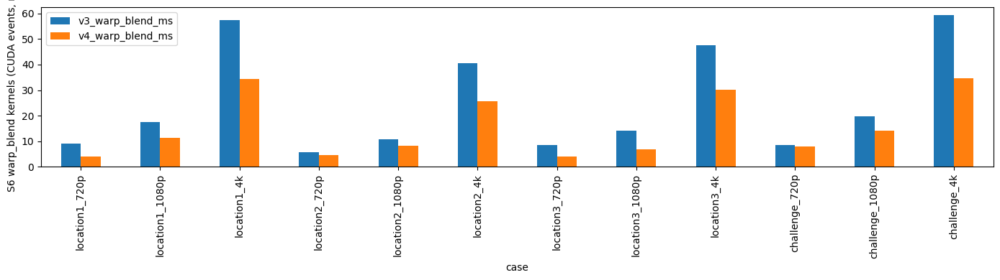

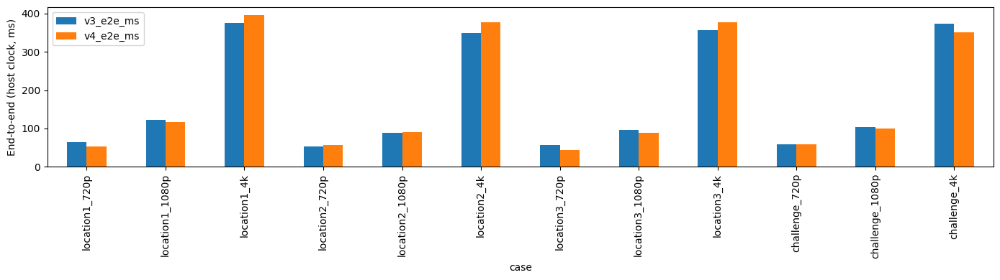

In [9]:
verified = timings.loc[timings.status.eq("ok") & timings.case_status.eq("ok") & timings.parity.eq("pass")]
comparison_rows = []
for case, group in verified.groupby("case", sort=False):
    by_v = {int(r["version"]): r for r in group.to_dict("records")}
    if not all(v in by_v for v in (0, 3, 4)):
        continue
    v0, v3, v4 = [by_v[v] for v in (0, 3, 4)]
    comparison_rows.append({"case": case, "resolution": v3["resolution"],
        "v3_warp_blend_ms": v3["warp_blend"], "v4_warp_blend_ms": v4["warp_blend"],
        "warp_delta_ms": v3["warp_blend"]-v4["warp_blend"],
        "warp_speedup": v3["warp_blend"]/v4["warp_blend"] if v4["warp_blend"] > 0 else float("nan"),
        "v3_kernel_ms": v3["kernel_total"], "v4_kernel_ms": v4["kernel_total"],
        "kernel_speedup": v3["kernel_total"]/v4["kernel_total"] if v4["kernel_total"] > 0 else float("nan"),
        "v3_e2e_ms": v3["end_to_end"], "v4_e2e_ms": v4["end_to_end"],
        "e2e_delta_ms": v3["end_to_end"]-v4["end_to_end"],
        "e2e_speedup": v3["end_to_end"]/v4["end_to_end"],
        "e2e_speedup_v0_v4": v0["end_to_end"]/v4["end_to_end"],
        "v3_warp_share_kernel_pct": 100*v3["warp_blend"]/v3["kernel_total"],
        "v3_warp_share_e2e_pct": 100*v3["warp_blend"]/v3["end_to_end"],
        "e2e_if_only_warp_changed_ms": v3["end_to_end"]-v3["warp_blend"]+v4["warp_blend"],
        "v3_largest_stage": max(STAGES, key=lambda s: v3["stage_"+s]),
        "v4_largest_stage": max(STAGES, key=lambda s: v4["stage_"+s])})
comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(INSPECTION_DIR / "comparison.csv", index=False)
if not comparison.empty:
    display(comparison[["case", "v3_warp_blend_ms", "v4_warp_blend_ms", "warp_delta_ms", "warp_speedup",
                        "v3_kernel_ms", "v4_kernel_ms", "kernel_speedup",
                        "v3_warp_share_kernel_pct", "v3_largest_stage", "v4_largest_stage"]].round(4))
    display(comparison[["case", "v3_e2e_ms", "v4_e2e_ms", "e2e_delta_ms", "e2e_speedup",
                        "e2e_speedup_v0_v4", "e2e_if_only_warp_changed_ms"]].round(4))
    speedup_cols = ["warp_speedup", "kernel_speedup", "e2e_speedup", "e2e_speedup_v0_v4"]
    by_resolution = comparison.groupby("resolution", sort=False)[speedup_cols].agg(geometric_mean)
    by_resolution.to_csv(INSPECTION_DIR / "comparison_by_resolution.csv")
    display(by_resolution.round(4))
    print(f"S6 warp_blend V4 nhanh hơn: {(comparison.warp_speedup>1).sum()}/{len(comparison)} case.")
    print(f"Tổng kernel V4 nhanh hơn: {(comparison.kernel_speedup>1).sum()}/{len(comparison)} case.")
    print(f"E2E V4 nhanh hơn: {(comparison.e2e_speedup>1).sum()}/{len(comparison)} case.")
    slower = comparison.loc[comparison.warp_speedup.lt(1), ["case", "v3_warp_blend_ms", "v4_warp_blend_ms", "warp_speedup"]]
    if not slower.empty:
        print("Các case S6 warp_blend V4 chậm hơn:")
        display(slower.round(4))
    for cols, ylabel in [(["v3_warp_blend_ms", "v4_warp_blend_ms"], "S6 warp_blend kernels (CUDA events, ms)"),
                          (["v3_e2e_ms", "v4_e2e_ms"], "End-to-end (host clock, ms)")]:
        comparison.set_index("case")[cols].plot.bar(figsize=(14,4), ylabel=ylabel)
        plt.tight_layout()
        plt.show()
else:
    print("Chưa có case đủ điều kiện so sánh. Xem failures/logs; không kết luận speedup.")

### 7.2 Inspect một case: toàn bộ bước, S1–S6 và bottleneck

Đổi `INSPECT_CASE` thành tên bất kỳ trong danh sách. Xem cả bước không đổi: nếu RANSAC/copy/residual biến động lớn thì E2E chưa cô lập được hoàn toàn hiệu quả S6. Các dòng step, stage và total là các cách phân rã khác nhau, không cộng chồng.

Cases: ['location1_720p', 'location1_1080p', 'location1_4k', 'location2_720p', 'location2_1080p', 'location2_4k', 'location3_720p', 'location3_1080p', 'location3_4k', 'challenge_720p', 'challenge_1080p', 'challenge_4k']
GPU: Tesla T4, GPU-cb2554e3-0e82-6a06-cb8a-0af77ec143e2, 580.82.07
 
Case: location1_4k


,V0_ms,V3_ms,V4_ms,saved_V3_minus_V4_ms,speedup_V3_over_V4
gray,37.04341,0.51477,0.52348,-0.00871,0.98336
blur,542.17368,1.35870,1.51059,-0.15189,0.89945
harris,789.25259,4.09549,4.34806,-0.25257,0.94191
nms_topk,44.55809,1.33311,1.45188,-0.11876,0.91820
describe,26.68956,0.53067,0.53793,-0.00726,0.98650
match,3667.08839,0.62939,0.68335,-0.05396,0.92104
ransac,34.00568,12.70646,13.71332,-1.00686,0.92658
warp_blend,2893.14384,57.38608,34.32495,23.06113,1.67185
kernel_total,0.00000,78.55468,57.09356,21.46111,1.37589
h2d,0.00000,83.39137,90.44819,-7.05681,0.92198


,V0_ms,V3_ms,V4_ms,saved_V3_minus_V4_ms,speedup_V3_over_V4
stage_S1,579.21709,1.87347,2.03407,-0.16060,0.92104
stage_S2,833.81068,5.42860,5.79994,-0.37133,0.93598
stage_S3,26.68956,0.53067,0.53793,-0.00726,0.98650
stage_S4,3667.08839,0.62939,0.68335,-0.05396,0.92104
stage_S5,34.00568,12.70646,13.71332,-1.00686,0.92658
stage_S6,2893.14384,57.38608,34.32495,23.06113,1.67185


,version,status,parity,runs,warmup_runs,keypoints_A,keypoints_B,matches,inliers,inlier_ratio
6,0,ok,pass,5,1,3000,3000,1393,865,0.620962
7,3,ok,pass,5,1,3000,3000,1393,865,0.620962
8,4,ok,pass,5,1,3000,3000,1393,865,0.620962


Xếp hạng các bước kernel:


,version,step,ms,kernel_share_pct,e2e_share_pct
7,3,warp_blend,57.3861,73.0524,15.3102
6,3,ransac,12.7065,16.1753,3.3900
2,3,harris,4.0955,5.2136,1.0927
1,3,blur,1.3587,1.7296,0.3625
3,3,nms_topk,1.3331,1.6971,0.3557
5,3,match,0.6294,0.8012,0.1679
4,3,describe,0.5307,0.6755,0.1416
0,3,gray,0.5148,0.6553,0.1373
15,4,warp_blend,34.3249,60.1205,8.6491
14,4,ransac,13.7133,24.0190,3.4554


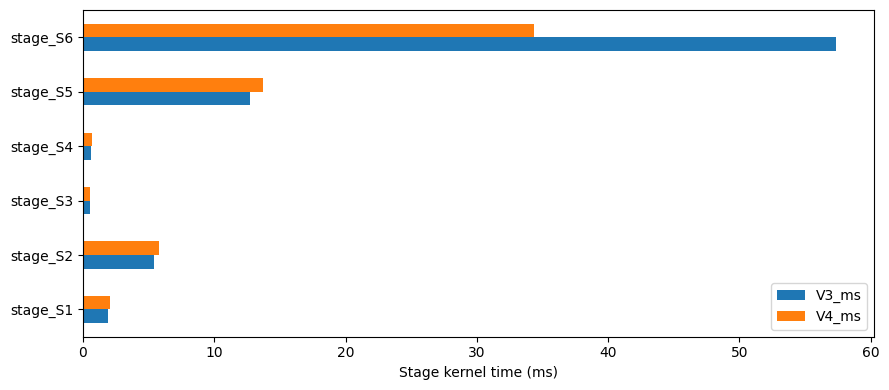

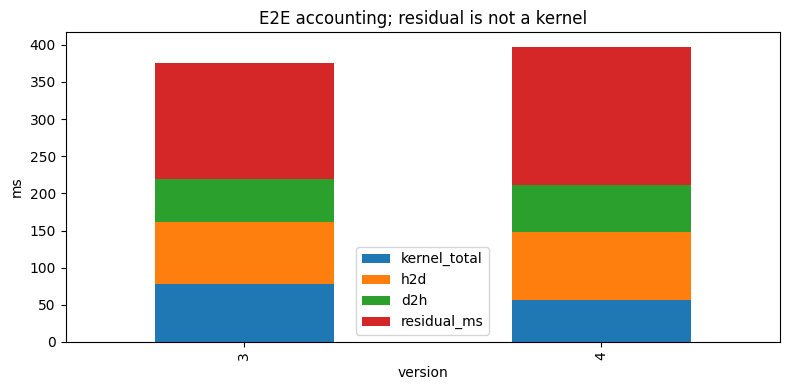

Panorama V3


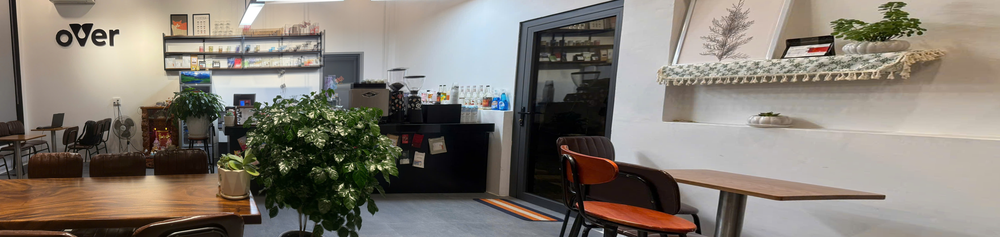

Panorama V4


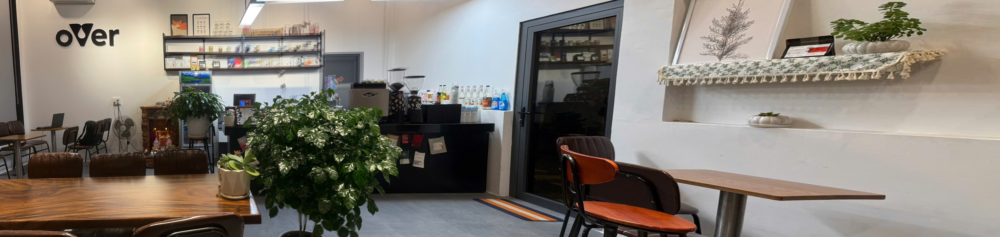

In [10]:
print("Cases:", list(timings.case.unique()))
INSPECT_CASE = "location1_4k"

def inspect_case(case):
    chosen = timings.loc[timings.case.eq(case) & timings.status.eq("ok")]
    if chosen.empty:
        print("Không có timing thành công cho", case)
        return
    def compare_metrics(metrics):
        table = chosen.set_index("version")[metrics].T.reindex(columns=[0,3,4])
        table.columns = ["V0_ms", "V3_ms", "V4_ms"]
        table["saved_V3_minus_V4_ms"] = table.V3_ms-table.V4_ms
        table["speedup_V3_over_V4"] = table.V3_ms / table.V4_ms.where(table.V4_ms.gt(0))
        return table
    print("GPU:", GPU_LABEL, "\nCase:", case)
    if not chosen.parity.eq("pass").all() or not chosen.case_status.eq("ok").all():
        print("UNVERIFIED: timing vẫn được hiển thị để chẩn đoán; không dùng để kết luận tăng tốc.")
    step_table = compare_metrics(TIMING_FIELDS)
    stage_table = compare_metrics(["stage_"+s for s in STAGES])
    display(step_table.round(5))
    display(stage_table.round(5))
    display(chosen.reindex(columns=["version", "status", "parity", "runs", "warmup_runs",
                                   "keypoints_A", "keypoints_B", "matches", "inliers", "inlier_ratio"]))
    step_table.to_csv(INSPECTION_DIR / f"{case}_step_comparison.csv")
    stage_table.to_csv(INSPECTION_DIR / f"{case}_stage_comparison.csv")
    ranks = []
    for r in chosen.loc[chosen.version.isin([3,4])].to_dict("records"):
        for name in STEPS:
            ranks.append({"version": r["version"], "step": name, "ms": r[name],
                          "kernel_share_pct": 100*r[name]/r["kernel_total"],
                          "e2e_share_pct": 100*r[name]/r["end_to_end"]})
    if not ranks:
        return
    ranked = pd.DataFrame(ranks).sort_values(["version", "ms"], ascending=[True,False])
    print("Xếp hạng các bước kernel:")
    display(ranked.round(4))
    ranked.to_csv(INSPECTION_DIR / f"{case}_bottleneck_ranking.csv", index=False)
    stage_table[["V3_ms", "V4_ms"]].plot.barh(figsize=(9,4), xlabel="Stage kernel time (ms)")
    plt.tight_layout()
    plt.show()
    system = chosen.loc[chosen.version.isin([3,4])].set_index("version")
    system[["kernel_total", "h2d", "d2h", "residual_ms"]].plot.bar(stacked=True, figsize=(8,4), ylabel="ms")
    plt.title("E2E accounting; residual is not a kernel")
    plt.tight_layout()
    plt.show()
    for version in (3,4):
        image_path = RESULTS / f"{case}_v{version}.png"
        if image_path.is_file():
            print(f"Panorama V{version}")
            with Image.open(image_path) as image:
                display(image.copy())
inspect_case(INSPECT_CASE)


### 7.3 Kiểm tra thứ tự đo / chạy lại

Bật RUN_REVERSE_SWEEP=True ở cell đầu để thu thêm sweep đảo thứ tự. Bảng so độ ổn định của blur và E2E giữa hai sweep. JSON chỉ có trung bình, không có độ lệch chuẩn/min từng iteration; không suy ra ý nghĩa thống kê từ một số trung bình.


In [11]:
if RUN_REVERSE_SWEEP and (REVERSE_RESULTS / "summary.csv").is_file():
    reverse_summary = pd.read_csv(REVERSE_RESULTS / "summary.csv")
    valid_forward = summary.loc[summary.status.eq("ok") & summary.parity.eq("pass")]
    valid_reverse = reverse_summary.loc[reverse_summary.status.eq("ok") & reverse_summary.parity.eq("pass")]
    order_columns = ["case", "warp_blend_speedup_v3_v4", "e2e_speedup_v3_v4"]
    order_check = valid_forward[order_columns].merge(valid_reverse[order_columns], on="case", suffixes=("_forward", "_reverse"))
    order_check.to_csv(INSPECTION_DIR / "order_check.csv", index=False)
    display(order_check.round(4))
else:
    print("NOT RUN: reverse sweep. Bật RUN_REVERSE_SWEEP để kiểm tra bias thứ tự/clock.")


,case,warp_blend_speedup_v3_v4_forward,e2e_speedup_v3_v4_forward,warp_blend_speedup_v3_v4_reverse,e2e_speedup_v3_v4_reverse
0,location1_720p,2.3166,1.1976,1.0979,0.8789
1,location1_1080p,1.5482,1.0557,1.4137,1.1723
2,location1_4k,1.6718,0.9445,1.6839,0.9436
3,location2_720p,1.2116,0.9293,2.0015,1.1634
4,location2_1080p,1.2834,0.9682,1.7212,0.9999
5,location2_4k,1.5808,0.9234,1.6704,1.0432
6,location3_720p,2.0517,1.2843,1.1018,0.9105
7,location3_1080p,2.0643,1.0889,1.5092,1.1636
8,location3_4k,1.5838,0.9447,1.6536,0.9668
9,challenge_720p,1.0672,0.9982,2.1967,1.2340


## 8. Profiler V3/V4: các kernel S6 (`warp_blend`, `pack_uchar4`, `crop`) và API/Memory

Nsight Systems thu từng kernel thực chạy để tách riêng thời gian `warp_blend_kernel` (V3) vs `pack_rgb_to_uchar4_kernel` + `warp_blend_v4_kernel` (V4), cũng như phần histogram/crop của S6 và `cuda_api_sum`/`cuda_gpu_mem_time_sum` cho phần copy/API ngoài kernel.

In [12]:
PROFILE_DIR = SESSION_DIR / "profiles"
PROFILE_DIR.mkdir(exist_ok=True)
PROFILE_CASES = [("location1", "medium_1080p", "location1_1080p"),
                 ("location1", "large_4k", "location1_4k")]

def read_kernel_summary(output):
    rows, columns = [], None
    for values in csv.reader(output.splitlines()):
        values = [v.strip().lstrip("﻿") for v in values]
        if {"Total Time (ns)", "Instances", "Name"} <= set(values):
            columns = values
        elif columns is not None and len(values) == len(columns):
            row = dict(zip(columns, values))
            if row["Instances"].replace(",", "").isdigit():
                rows.append({"name": row["Name"],
                             "total_ns": float(row["Total Time (ns)"].replace(",", "")),
                             "instances": int(row["Instances"].replace(",", ""))})
    if not rows:
        raise RuntimeError("Không đọc được kernel CSV. Xem log Nsight; không đánh dấu profiling PASS.")
    return rows

def s6_part(name):
    if "pack_rgb_to_uchar4_kernel" in name:
        return "pack_uchar4"
    if "warp_blend_v4_kernel" in name or "warp_blend_kernel" in name:
        return "warp_blend"
    if "build_crop_histograms_kernel" in name:
        return "crop_hist"
    if "find_crop_rows" in name or "compressed_stack" in name:
        return "crop_scan"
    if "reduce_crop_rows_kernel" in name:
        return "crop_reduce"
    if "crop_image_kernel" in name:
        return "crop_copy"
    if "prepare_canvas_kernel" in name:
        return "prepare"
    return "other"

def profile_s6(scene, resolution, case, version):
    prefix = PROFILE_DIR / f"nsys_v{version}_{case}"
    left = Path("dataset") / scene / resolution / "1.jpg"
    right = left.with_name("2.jpg")
    print("PROFILE GPU:", GPU_LABEL, "case:", case, "version:", version)
    run(["nsys", "profile", "--trace=cuda", "--sample=none", "--force-overwrite=true",
         "-o", prefix, "build/stitch_v4", left, right,
         PROFILE_DIR / f"{case}_v{version}.png", "--version", version, "--runs", RUNS],
        log=prefix.with_suffix(".log"))
    report = prefix.with_suffix(".nsys-rep")
    if not report.is_file():
        raise RuntimeError("Thiếu nsys report: " + str(report))
    stats_log = prefix.with_name(prefix.name + "_kernel_stats.log")
    run(["nsys", "stats", "--report", "cuda_gpu_kern_sum", "--format", "csv",
         "--output", "-", report], log=stats_log)
    kernels = read_kernel_summary(stats_log.read_text(encoding="utf-8"))
    for row in kernels:
        row["part"] = s6_part(row["name"])
        row["trace_total_ms"] = row["total_ns"] / 1e6
        row["per_pipeline_ms"] = row["trace_total_ms"] / (RUNS+1)
        row["avg_launch_us"] = row["total_ns"] / row["instances"] / 1e3
    table = pd.DataFrame(kernels).sort_values("total_ns", ascending=False)
    table.to_csv(prefix.with_name(prefix.name + "_kernels.csv"), index=False)
    print("Mọi kernel, xếp theo tổng thời gian trace:")
    display(table[["name", "instances", "avg_launch_us", "per_pipeline_ms", "part"]].round(5))
    s6_parts = ("prepare", "pack_uchar4", "warp_blend", "crop_hist", "crop_scan", "crop_reduce", "crop_copy")
    parts = {}
    for part in s6_parts:
        matched = [r for r in kernels if r["part"] == part]
        parts[part+"_ms"] = sum(r["per_pipeline_ms"] for r in matched)
    if not any("nearest_tiled_kernel" in r["name"] for r in kernels):
        raise RuntimeError("Trace thiếu matching V2; kiểm tra đúng source tích lũy.")
    # Retain memory/API summaries too, including allocation/synchronization.
    extra_log = prefix.with_name(prefix.name + "_api_memory.log")
    extra_code = run(["nsys", "stats", "--report", "cuda_api_sum,cuda_gpu_mem_time_sum",
                      "--format", "csv", "--output", "-", report], check=False, log=extra_log)
    if extra_code:
        print("NOT AVAILABLE: API/memory report; kernel CSV vẫn được lưu.")
    return {"case": case, "version": version, **parts,
            "warp_only_ms": parts["pack_uchar4_ms"] + parts["warp_blend_ms"],
            "s6_total_kernel_ms": sum(parts.values()),
            "all_kernel_ms": sum(r["per_pipeline_ms"] for r in kernels)}

profile_rows = []
profile_status = {"requested": RUN_PROFILER, "tool_available": bool(shutil.which("nsys")), "cases": []}
if RUN_PROFILER and shutil.which("nsys"):
    for scene, resolution, case in PROFILE_CASES:
        eligible = summary.loc[summary.case.eq(case) & summary.status.eq("ok") & summary.parity.eq("pass")]
        if eligible.empty:
            profile_status["cases"].append({"case": case, "status": "UNVERIFIED / SKIPPED"})
            continue
        for version in (3,4):
            profile_rows.append(profile_s6(scene, resolution, case, version))
            pd.DataFrame(profile_rows).to_csv(PROFILE_DIR / "s6_parts.csv", index=False)
        profile_status["cases"].append({"case": case, "status": "collected"})
    if profile_rows:
        profiles = pd.DataFrame(profile_rows)
        display(profiles.round(5))
        profile_comparison = []
        for case, group in profiles.groupby("case", sort=False):
            versions = {int(r["version"]): r for r in group.to_dict("records")}
            if not all(v in versions for v in (3,4)):
                continue
            for part in ("warp_only_ms", "warp_blend_ms", "pack_uchar4_ms", "crop_hist_ms", "crop_scan_ms", "s6_total_kernel_ms"):
                a, b = versions[3][part], versions[4][part]
                profile_comparison.append({"case": case, "part": part, "V3_ms": a, "V4_ms": b,
                                           "saved_ms": a-b, "speedup": a/b if b>0 else None})
        profile_comparison = pd.DataFrame(profile_comparison)
        profile_comparison.to_csv(PROFILE_DIR / "s6_profile_comparison.csv", index=False)
        display(profile_comparison.round(5))
else:
    print("NOT RUN: Nsight profiling. Cần runtime có nsys; không kết luận nguyên nhân memory/occupancy khi chưa có evidence.")
(PROFILE_DIR / "status.json").write_text(json.dumps(profile_status, indent=2), encoding="utf-8")

PROFILE GPU: Tesla T4, GPU-cb2554e3-0e82-6a06-cb8a-0af77ec143e2, 580.82.07
 case: location1_1080p version: 3
$ nsys profile --trace=cuda --sample=none --force-overwrite=true -o out/v4_inspect_20261124T112533_222735Z/profiles/nsys_v3_location1_1080p build/stitch_v4 dataset/location1/medium_1080p/1.jpg dataset/location1/medium_1080p/2.jpg out/v4_inspect_20261124T112533_222735Z/profiles/location1_1080p_v3.png --version 3 --runs 5
version=3 runs=5 imageA=1920x1080 imageB=1920x1080
keypoints_A=1956 keypoints_B=2283 matches=973 inliers=689
panorama=4444x1080 inlier_ratio=0.708
avg_ms gray=0.171 blur=0.488 harris=1.224 nms_topk=0.668 describe=0.278 match=0.553 ransac=12.692 warp_blend=16.918 h2d=21.928 d2h=15.348 kernel_total=32.992 end_to_end=105.056
Generating '/tmp/nsys-report-68d8.qdstrm'

[1/1] [0%                          ] nsys_v3_location1_1080p.nsys-rep
[1/1] [0%                          ] nsys_v3_location1_1080p.nsys-rep
[1/1] [================71%         ] nsys_v3_location1_1080p.n

,name,instances,avg_launch_us,per_pipeline_ms,part
0,"<unnamed>::warp_blend_kernel(const unsigned char *, int, int, const unsigned char *, i...",6,14905.55567,14.90556,warp_blend
1,"<unnamed>::refine_best_kernel(const stage5::Point *, const stage5::Point *, const int ...",6,6290.79900,6.29080,other
2,"<unnamed>::generate_samples_kernel(const int *, int *)",6,5061.46917,5.06147,other
3,"<unnamed>::find_crop_rows_compressed_stack_kernel(const int *, int, int, unsigned int ...",6,2289.18067,2.28918,crop_scan
4,"<unnamed>::score_hypotheses_kernel(const stage5::Point *, const stage5::Point *, const...",6,1676.14517,1.67615,other
5,"<unnamed>::harris_response_kernel(const float *, const float *, const float *, float *...",12,465.22317,0.93045,other
6,"<unnamed>::compact_points_kernel(const Keypoint *, const Keypoint *, const Match *, co...",6,490.39850,0.49040,other
7,"<unnamed>::build_crop_histograms_kernel(const unsigned char *, int, int, int *)",6,392.36883,0.39237,crop_hist
8,"<unnamed>::nearest_tiled_kernel(const Descriptor *, int, const Descriptor *, int, int ...",12,164.68675,0.32937,other
9,"<unnamed>::tensor_kernel(const float *, float *, float *, float *, int, int)",12,146.03625,0.29207,other


$ nsys stats --report cuda_api_sum,cuda_gpu_mem_time_sum --format csv --output - out/v4_inspect_20261124T112533_222735Z/profiles/nsys_v3_location1_1080p.nsys-rep

         File is older than input file: out/v4_inspect_20261124T112533_222735Z/profiles/nsys_v3_location1_1080p.nsys-rep
         Use --force-export=true to update export file.

usage: nsys stats [<args>] <input-file>
Try 'nsys stats --help' for more information.
NOT AVAILABLE: API/memory report; kernel CSV vẫn được lưu.
PROFILE GPU: Tesla T4, GPU-cb2554e3-0e82-6a06-cb8a-0af77ec143e2, 580.82.07
 case: location1_1080p version: 4
$ nsys profile --trace=cuda --sample=none --force-overwrite=true -o out/v4_inspect_20261124T112533_222735Z/profiles/nsys_v4_location1_1080p build/stitch_v4 dataset/location1/medium_1080p/1.jpg dataset/location1/medium_1080p/2.jpg out/v4_inspect_20261124T112533_222735Z/profiles/location1_1080p_v4.png --version 4 --runs 5
version=4 runs=5 imageA=1920x1080 imageB=1920x1080
keypoints_A=1956 keypoints_B=228

,name,instances,avg_launch_us,per_pipeline_ms,part
0,"<unnamed>::warp_blend_v4_kernel(const unsigned char *, int, int, const uchar4 *, int, ...",6,7306.98683,7.30699,warp_blend
1,"<unnamed>::refine_best_kernel(const stage5::Point *, const stage5::Point *, const int ...",6,6355.80483,6.35580,other
2,"<unnamed>::generate_samples_kernel(const int *, int *)",6,5112.47083,5.11247,other
3,"<unnamed>::find_crop_rows_compressed_stack_kernel(const int *, int, int, unsigned int ...",6,2279.72450,2.27972,crop_scan
4,"<unnamed>::score_hypotheses_kernel(const stage5::Point *, const stage5::Point *, const...",6,1699.01383,1.69901,other
5,"<unnamed>::harris_response_kernel(const float *, const float *, const float *, float *...",12,501.06500,1.00213,other
6,"<unnamed>::compact_points_kernel(const Keypoint *, const Keypoint *, const Match *, co...",6,496.16367,0.49616,other
7,"<unnamed>::build_crop_histograms_kernel(const unsigned char *, int, int, int *)",6,384.98783,0.38499,crop_hist
8,"<unnamed>::nearest_tiled_kernel(const Descriptor *, int, const Descriptor *, int, int ...",12,167.07067,0.33414,other
9,"<unnamed>::tensor_kernel(const float *, float *, float *, float *, int, int)",12,145.52992,0.29106,other


$ nsys stats --report cuda_api_sum,cuda_gpu_mem_time_sum --format csv --output - out/v4_inspect_20261124T112533_222735Z/profiles/nsys_v4_location1_1080p.nsys-rep

         File is older than input file: out/v4_inspect_20261124T112533_222735Z/profiles/nsys_v4_location1_1080p.nsys-rep
         Use --force-export=true to update export file.

usage: nsys stats [<args>] <input-file>
Try 'nsys stats --help' for more information.
NOT AVAILABLE: API/memory report; kernel CSV vẫn được lưu.
PROFILE GPU: Tesla T4, GPU-cb2554e3-0e82-6a06-cb8a-0af77ec143e2, 580.82.07
 case: location1_4k version: 3
$ nsys profile --trace=cuda --sample=none --force-overwrite=true -o out/v4_inspect_20261124T112533_222735Z/profiles/nsys_v3_location1_4k build/stitch_v4 dataset/location1/large_4k/1.jpg dataset/location1/large_4k/2.jpg out/v4_inspect_20261124T112533_222735Z/profiles/location1_4k_v3.png --version 3 --runs 5
version=3 runs=5 imageA=3840x2160 imageB=3840x2160
keypoints_A=3000 keypoints_B=3000 matches=1393 in

,name,instances,avg_launch_us,per_pipeline_ms,part
0,"<unnamed>::warp_blend_kernel(const unsigned char *, int, int, const unsigned char *, i...",6,60516.22967,60.51623,warp_blend
1,"<unnamed>::refine_best_kernel(const stage5::Point *, const stage5::Point *, const int ...",6,8277.28783,8.27729,other
2,"<unnamed>::find_crop_rows_compressed_stack_kernel(const int *, int, int, unsigned int ...",6,5311.71850,5.31172,crop_scan
3,"<unnamed>::generate_samples_kernel(const int *, int *)",6,4958.42650,4.95843,other
4,"<unnamed>::harris_response_kernel(const float *, const float *, const float *, float *...",12,1828.50650,3.65701,other
5,"<unnamed>::build_crop_histograms_kernel(const unsigned char *, int, int, int *)",6,2403.43883,2.40344,crop_hist
6,"<unnamed>::score_hypotheses_kernel(const stage5::Point *, const stage5::Point *, const...",6,2372.50633,2.37251,other
7,"<unnamed>::tensor_kernel(const float *, float *, float *, float *, int, int)",12,609.81158,1.21962,other
8,"<unnamed>::max_response_kernel(const float *, int, float *)",24,230.94488,0.92378,other
9,"void <unnamed>::gaussian_blur_kernel<(bool)1>(const float *, float *, int, int, const ...",12,413.69617,0.82739,other


... (2 outputs left out)

$ nsys stats --report cuda_api_sum,cuda_gpu_mem_time_sum --format csv --output - out/v4_inspect_20261124T112533_222735Z/profiles/nsys_v4_location1_4k.nsys-rep

         File is older than input file: out/v4_inspect_20261124T112533_222735Z/profiles/nsys_v4_location1_4k.nsys-rep
         Use --force-export=true to update export file.

usage: nsys stats [<args>] <input-file>
Try 'nsys stats --help' for more information.
NOT AVAILABLE: API/memory report; kernel CSV vẫn được lưu.


,case,version,prepare_ms,pack_uchar4_ms,warp_blend_ms,crop_hist_ms,crop_scan_ms,crop_reduce_ms,crop_copy_ms,warp_only_ms,s6_total_kernel_ms,all_kernel_ms
0,location1_1080p,3,0.01399,0.0000,14.90556,0.39237,2.28918,0.00700,0.19405,14.90556,17.80214,34.32997
1,location1_1080p,4,0.01262,0.0598,7.30699,0.38499,2.27972,0.00702,0.16698,7.36679,10.21813,26.99925
2,location1_4k,3,0.01398,0.0000,60.51623,2.40344,5.31172,0.01051,0.74735,60.51623,69.00323,95.08842
3,location1_4k,4,0.01113,0.2431,27.27123,2.41498,5.45491,0.01070,0.64582,27.51433,36.05188,59.41899


,case,part,V3_ms,V4_ms,saved_ms,speedup
0,location1_1080p,warp_only_ms,14.90556,7.36679,7.53877,2.02335
1,location1_1080p,warp_blend_ms,14.90556,7.30699,7.59857,2.03990
2,location1_1080p,pack_uchar4_ms,0.00000,0.05980,-0.05980,0.00000
3,location1_1080p,crop_hist_ms,0.39237,0.38499,0.00738,1.01917
4,location1_1080p,crop_scan_ms,2.28918,2.27972,0.00946,1.00415
5,location1_1080p,s6_total_kernel_ms,17.80214,10.21813,7.58401,1.74221
6,location1_4k,warp_only_ms,60.51623,27.51433,33.00190,2.19944
7,location1_4k,warp_blend_ms,60.51623,27.27123,33.24500,2.21905
8,location1_4k,pack_uchar4_ms,0.00000,0.24310,-0.24310,0.00000
9,location1_4k,crop_hist_ms,2.40344,2.41498,-0.01154,0.99522


211

## 9. Bàn giao và diễn giải

Tải toàn bộ `SESSION_DIR`: environment/build flags, command logs (đã giữ stdout/stderr), 36 JSON timing và panorama, summary/timings CSV, inspection CSV và Nsight reports nếu có. Đổi `INSPECT_CASE` để xem từng case; bật `RUN_REVERSE_SWEEP` nếu cần kiểm tra bias thứ tự.

Báo cáo riêng: (1) stage và bước chiếm nhiều thời gian ở V3 (S6 `warp_blend` ~73% kernel ở 4K); (2) thời gian `warp_blend` + `pack_uchar4` ở V4 thay đổi thế nào so với `warp_blend` V3; (3) `warp_blend` speedup, `kernel_total` speedup và E2E speedup; (4) copy H2D/D2H, residual và các bước S1–S5 không đổi có biến động không; (5) giới hạn E2E do phần copy/cấp phát ngoài kernel (hướng V5 device residency). Không ghép số đo giữa hai GPU session, không tự suy độ lệch chuẩn từ JSON chỉ có trung bình.